# Ok-k-mer

Use mumemto_env conda environment, else python310

## Imports

In [1]:
import os
from collections import Counter
from itertools import combinations, product

import numpy as np
import pandas as pd
pd.options.display.max_rows = 40

from matplotlib import pyplot as plt
from tqdm import tqdm

from ete3 import Tree

from mumemto.utils import MUMdata, get_sequence_lengths
import mumemto.utils as mum_utils

from random import sample, seed as set_seed, randint

from scipy.stats import binom, geom, pearsonr, spearmanr



from scipy.cluster.hierarchy import linkage, to_tree
from scipy.spatial.distance import squareform

/home/shwang45/miniconda3/envs/mumemto_env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mplpatches
%matplotlib inline

plt.rcParams['figure.dpi'] = 300
plt.rcParams['agg.path.chunksize'] = 10000

## Load Data

### Load cyano gtdb tree

In [3]:
def dist_tree_calc(filename1):
    ''' Calculate tree distance. '''
    tree1= Tree(filename1,format=1)
    # print('Tree from', filename1, 'len:', len(tree1))
    dist_tree={}
    samples = [i.name for i in tree1.get_leaves()]
    num_sample = len(samples)
    for i in range(num_sample):
        tax_i = samples[i]
        for j in range(i+1,num_sample):
            tax_j = samples[j]
            dist_tree[(min(tax_i, tax_j)+".fa", max(tax_i, tax_j)+".fa")] = tree1.get_distance(tax_i, tax_j, topology_only=False)
    return tree1, dist_tree


In [4]:
cyano_tree_path = "/vast/blangme2/sjhwang/mem_ani_data/cyano_gtdb/fasta/o__Cyanobacteriales.nwk"

# make tree distance dictionary
l = []
true_tree, dist_tree = dist_tree_calc(cyano_tree_path)
species_pair_list = list(dist_tree.keys())
dist_tree_list = [dist_tree[pair] for pair in species_pair_list]
for pair, dist in list(zip(species_pair_list, dist_tree_list)):
    l.append([*pair ,dist])

tree_len = {}
for g1, g2, dist in l:
    if g1 not in tree_len:
        tree_len[g1] = {}
    if g2 not in tree_len:
        tree_len[g2] = {}
    tree_len[g1][g2] = dist
    tree_len[g2][g1] = dist

genome_names = sorted(tree_len.keys())
genome_names

tree_len


{'GCF_014697575.1.fa': {'GCF_900009145.1.fa': 0.01497468,
  'GCA_003456035.1.fa': 0.08632867999999999,
  'GCA_001873365.1.fa': 0.09554868999999999,
  'GCF_900009265.2.fa': 0.09191009,
  'GCF_900009135.1.fa': 0.08759749,
  'GCA_003609755.1.fa': 0.09490975,
  'GCF_900010725.2.fa': 0.06036208,
  'GCA_903893625.1.fa': 0.06429838,
  'GCF_000972705.2.fa': 0.25726158,
  'GCF_000169095.1.fa': 0.26781448,
  'GCF_000478195.2.fa': 0.26675748,
  'GCA_012033335.1.fa': 0.30262208,
  'GCA_012516315.1.fa': 0.28190158,
  'GCA_016745315.2.fa': 0.28748658,
  'GCA_938083405.1.fa': 0.39359007999999995,
  'GCA_030064835.1.fa': 0.35157498,
  'GCA_022822685.1.fa': 0.38867317999999995,
  'GCF_014132355.1.fa': 0.37367121999999997,
  'GCF_010692555.1.fa': 0.37376312,
  'GCF_010672525.1.fa': 0.37431853000000004,
  'GCF_010672585.1.fa': 0.37459102,
  'GCF_003838195.1.fa': 0.37873517,
  'GCF_010672455.1.fa': 0.37608969999999997,
  'GCF_010672085.1.fa': 0.37130094999999996,
  'GCA_018457135.1.fa': 0.40566645,
  'GCA

In [5]:
print(true_tree.get_ascii(show_internal=True))



                           /-GCF_014697575.1
                        /1|
                       |   \-GCF_900009145.1
                       |
                       |      /-GCA_003456035.1
                     /1|     |
                    |  |   /1|      /-GCA_001873365.1
                    |  |  |  |   /1|
                    |  |  |  |  |   \-GCF_900009265.2
                    |  |  |   \1|
                    |   \1|     |   /-GCF_900009135.1
                    |     |      \1|
                    |     |         \-GCA_003609755.1
                  /1|     |
                 |  |     |   /-GCF_900010725.2
                 |  |      \1|
                 |  |         \-GCA_903893625.1
                 |  |
                 |  |      /-GCF_000972705.2
                 |  |   /1|
               /1|  |  |  |   /-GCF_000169095.1
              |  |   \1|   \1|
              |  |     |      \-GCF_000478195.2
              |  |     |
              |  |      \-GCA_012033335.1
         

### Load MUMs

In [6]:
# baseline (all partial mums of >20 length )
# bum_path = "/vast/blangme2/sjhwang/match_based_pangenome_ani/data/cyano_vikram/cyan.bumbl"

# n_50 (down to length of 2)
bum_path = "/vast/blangme2/sjhwang/match_based_pangenome_ani/data/cyano_subset_n50/cyano_n50.bumbl"
#mums_path = "/vast/blangme2/sjhwang/match_based_pangenome_ani/data/cyano_subset_n50/cyano_n50.mums"

# less filtered (all partial mums of >? length)
#bum_path = "/vast/blangme2/sjhwang/match_based_pangenome_ani/data/cyano_vikram/less_filt/cyan.bumbl"
#mums_path = "/vast/blangme2/sjhwang/match_based_pangenome_ani/data/cyano_vikram/less_filt/cyan.mums"
#lengths_path = "/vast/blangme2/sjhwang/match_based_pangenome_ani/data/cyano_vikram/less_filt/cyan.lengths"


In [ ]:
# streaming the MUMs as a BUM file
#   had to type cast some bumble as int within the utils.py code

def mum_parse(mum, dist_M):
    valid = np.where(mum.starts != -1)[0]
    for i in range(len(valid)):
        for j in range(i, len(valid)):
            dist_M[valid[i], valid[j]] += mum.length
    return dist_M


print(bum_path)

# start generator
mum_gen = mum_utils.stream_mums(bumbl_path, seq_idx=None, verbose=False, return_blocks=False)

# build initial MUM files
mum = next(mum_gen)
num_genomes = len(mum.starts)
dist_M = np.zeros((num_genomes, num_genomes))
dist_M = mum_parse(mum, dist_M)

# record the rest
for mum in mum_gen:
    dist_M = mum_parse(mum, dist_M)

dist_M

/vast/blangme2/sjhwang/match_based_pangenome_ani/data/cyano_vikram/cyan.bumbl


array([[1282109.,   50393.,   34539., ...,   41525.,   37134.,   39619.],
       [      0., 4359895.,   42585., ...,  217331.,  172663.,  191099.],
       [      0.,       0.,  684672., ...,   25292.,   22023.,   26839.],
       ...,
       [      0.,       0.,       0., ..., 2867671.,  112687.,  153513.],
       [      0.,       0.,       0., ...,       0., 2182198.,  193058.],
       [      0.,       0.,       0., ...,       0.,       0., 3884201.]])

In [7]:
# less filtered distance matrix

dist_path = "/vast/blangme2/sjhwang/match_based_pangenome_ani/data/cyano_vikram/less_filt/dist.npy"
dist_M = np.load(dist_path)

dist_M.shape
# dist_M_try

(585, 585)

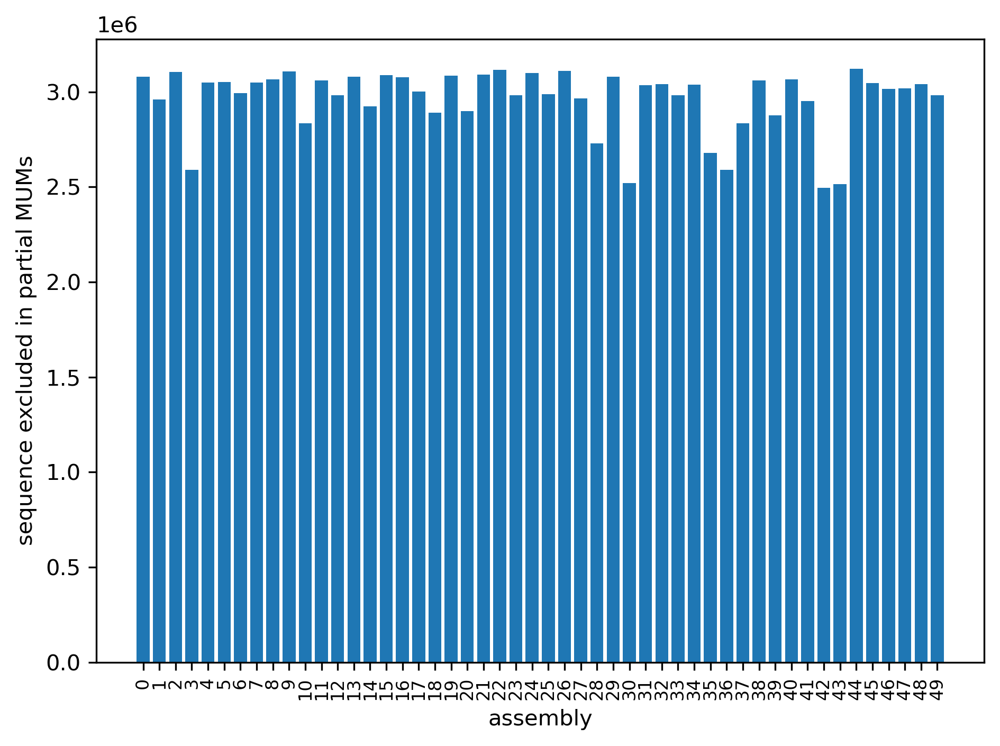

In [8]:
### count up which sequences are missing in partial MUMs, but weigh missing out on longer MUMs more
missing_mum, missing_seq = np.where(mums.starts == -1)
counts = np.bincount(missing_seq)
missing_lens = mums.lengths[missing_mum]

### plot
fig, ax = plt.subplots()
x = np.arange(mums.num_seqs)
# Label every bar with the sequence name, if possible:
if hasattr(mums, 'seq_names') and len(mums.seq_names) == mums.num_seqs:
    seq_labels = mums.seq_names
else:
    seq_labels = [str(i) for i in x]
bars = ax.bar(x, counts)
ax.set_xlabel('assembly')
ax.set_ylabel('sequence excluded in partial MUMs')
ax.set_xticks(x)
ax.set_xticklabels(seq_labels, rotation=90, fontsize=8)
fig.set_dpi(300)
plt.tight_layout()
plt.show()


## Calculate partial MUM to true tree distance correlation

In [8]:
# Correlation analysis between true tree distance and MUM distance matrix
# Extract pairwise distances from dist_M matrix and tree_len dictionary

mum_distances = []
tree_distances = []

genomes_ = sorted(list(tree_len.keys()))

# Get all pairs of genomes
for i in range(len(genomes_)):
    for j in range(i+1, len(genomes_)):
        # Get genome names
        genome_i = genomes_[i]
        genome_j = genomes_[j]

        # Get MUM distance from dist_M matrix
        mum_dist = dist_M[i, j]
        mum_distances.append(mum_dist)

        # Get true tree distance
        tree_dist = tree_len[genome_i][genome_j]
        tree_distances.append(tree_dist)


In [9]:
# Calculate Spearman correlation
corr, pval = spearmanr(tree_distances, mum_distances)

print(f"Spearman correlation between true tree distance and MUM distance: {corr:.4f}")
print(f"P-value: {pval:.2e}")
print(f"Number of genome pairs: {len(mum_distances)}")


Spearman correlation between true tree distance and MUM distance: -0.8220
P-value: 0.00e+00
Number of genome pairs: 170820


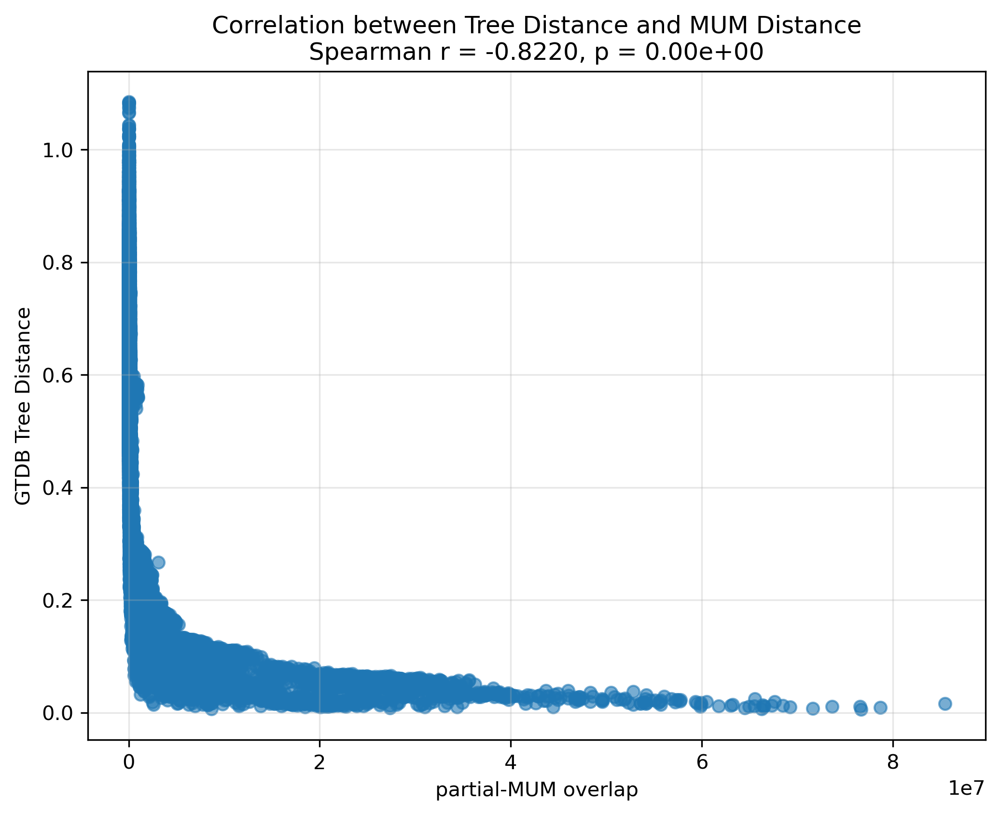

In [10]:
# plot correlation

plt.figure(figsize=(8, 6))
plt.scatter(mum_distances, tree_distances, alpha=0.6)
plt.ylabel('GTDB Tree Distance')
plt.xlabel('partial-MUM overlap')
plt.title(f'Correlation between Tree Distance and MUM Distance\nSpearman r = {corr:.4f}, p = {pval:.2e}')
plt.grid(True, alpha=0.3)
plt.show()

## Base UPGMA

In [16]:
def linkage_to_ete3_tree(linkage_matrix, labels):
    """
    Convert scipy linkage matrix to ete3 Tree object.

    Parameters:
    -----------
    linkage_matrix : ndarray
        The linkage matrix from scipy.cluster.hierarchy.linkage
    labels : list
        List of leaf labels

    Returns:
    --------
    Tree : ete3.Tree
        The phylogenetic tree
    """
    # Convert to scipy tree structure
    scipy_tree = to_tree(linkage_matrix, rd=False)

    def build_newick(node, parent_dist, leaf_names):
        """Recursively build Newick string."""
        if node.is_leaf():
            return f"{leaf_names[node.id]}:{parent_dist - node.dist:.6f}"
        else:
            left = build_newick(node.left, node.dist, leaf_names)
            right = build_newick(node.right, node.dist, leaf_names)
            return f"({left},{right}):{parent_dist - node.dist:.6f}"

    # Build Newick string
    newick_str = build_newick(scipy_tree, scipy_tree.dist, labels) + ";"

    # Create ete3 Tree from Newick string
    tree = Tree(newick_str, format=1)
    return tree


In [17]:
# Build UPGMA tree from simulated distance matrix

def build_upgma_tree(dist_matrix, tree_labels):
    """
    Build a UPGMA tree from a full distance matrix and labels.
    Returns the ete3 tree object.
    """
    from scipy.spatial.distance import squareform
    from scipy.cluster.hierarchy import linkage

    # Convert to condensed form (upper triangle as 1D array)
    condensed_dist = squareform(dist_matrix)

    # Build UPGMA tree using average linkage (UPGMA)
    linkage_matrix = linkage(condensed_dist, method='average')

    # Build the tree
    upgma_tree = linkage_to_ete3_tree(linkage_matrix, tree_labels)

    print("UPGMA tree built successfully!")
    print(f"Number of leaves: {len(upgma_tree.get_leaves())}")
    print("\nTree in Newick format:")
    print(upgma_tree.write(format=1))

    # Display the tree
    print("\nTree visualization:")
    print(upgma_tree.get_ascii(show_internal=True))
    return upgma_tree

# Usage example:
# upgma_tree = build_upgma_tree(mum_dist_matrix, sorted(tree_len.keys()))

In [18]:
# Convert mum_distances (condensed distance vector) into a symmetric distance matrix
N = len(genomes_)
mum_dist_matrix = np.zeros((N, N))

idx = 0
for i in range(N):
    for j in range(i + 1, N):
        mum_dist_matrix[i, j] = mum_distances[idx]
        mum_dist_matrix[j, i] = mum_distances[idx]
        idx += 1
# mum_dist_matrix

tree_labels = [_.rstrip('.fa') for _ in genomes_]
upgma_tree = build_upgma_tree(mum_dist_matrix, tree_labels)


UPGMA tree built successfully!
Number of leaves: 585

Tree in Newick format:
(GCF_020829645.1:3.6507e+06,(GCF_020829495.1:3.50676e+06,(GCF_002813575.1:3.26033e+06,(GCF_002246015.1:3.18778e+06,(GCF_015206895.1:3.07362e+06,(GCF_017114995.1:2.99823e+06,(GCF_014698505.1:2.94437e+06,(GCF_009873495.1:2.84708e+06,(GCA_003326195.1:2.78422e+06,(GCA_020829665.1:2.72574e+06,(GCF_020829625.1:2.65034e+06,(GCF_017114945.1:2.60452e+06,(GCF_017115025.1:2.54444e+06,(GCF_015206985.1:2.48407e+06,(GCF_001712795.1:2.40934e+06,(GCA_020829585.1:2.35259e+06,(GCA_015206945.1:2.29723e+06,(GCA_023522315.1:2.24824e+06,(GCA_020829485.1:2.16619e+06,(GCF_000020025.1:2.11568e+06,(GCF_028623165.1:2.0558e+06,(GCF_014023275.1:1.99251e+06,(GCF_017115165.1:1.93764e+06,(GCF_014698795.1:1.89502e+06,(GCF_003443655.1:1.83267e+06,(GCF_014222285.1:1.77716e+06,(GCF_030382115.1:1.72516e+06,(GCF_017114985.1:1.67861e+06,(GCF_002245985.1:1.61592e+06,(GCF_003113895.1:1.55593e+06,(GCF_013393905.1:1.5123e+06,(GCA_019359245.1:1.45862e+0

In [19]:
# compare true tree vs UPGMA tree
result = true_tree.robinson_foulds(upgma_tree)
rf_distance = result[0]
max_rf = result[1]

nrf = rf_distance / max_rf if max_rf > 0 else 0.0

print(f"Robinson-Foulds distance (rf): {rf_distance}")
print(f"Maximum possible RF distance (max_rf): {max_rf}")
print(f"Normalized Robinson-Foulds (nRF) distance between true tree and UPGMA tree: {nrf:.4f}")
# result


Robinson-Foulds distance (rf): 1166
Maximum possible RF distance (max_rf): 1166
Normalized Robinson-Foulds (nRF) distance between true tree and UPGMA tree: 1.0000


## MUM-informed bottom-up agglomerative tree building

In [29]:
# track the pairwise shared_seq of the all sets of partial MUMs

bum_path = "/vast/blangme2/sjhwang/match_based_pangenome_ani/data/cyano_vikram/cyan.bumbl"
# bum_path = "/vast/blangme2/sjhwang/match_based_pangenome_ani/data/cyano_subset_n50/cyano_n50.bumbl"
print(bum_path)

# start generator
mum_gen = mum_utils.stream_mums(bum_path, seq_idx=None, verbose=False, return_blocks=False)

genome_partial_mum_tracker = dict()
for mum in mum_gen:
    # Get MUM length and start positions for this MUM
    valid = np.where(mum.starts != -1)[0] # Find valid positions (not -1)
    key = frozenset(valid)
    genome_partial_mum_tracker[key] = genome_partial_mum_tracker.get(key, 0) + mum.length

genome_partial_mum_tracker

/vast/blangme2/sjhwang/match_based_pangenome_ani/data/cyano_vikram/cyan.bumbl


{frozenset({59, 66}): 149054,
 frozenset({351, 359}): 1783718,
 frozenset({110, 158}): 1518677,
 frozenset({420, 426}): 1013698,
 frozenset({48, 51}): 71571,
 frozenset({126, 505}): 641,
 frozenset({147, 173}): 2342645,
 frozenset({365, 512}): 141080,
 frozenset({401, 444}): 1200937,
 frozenset({24, 203}): 971564,
 frozenset({321, 407, 464}): 250579,
 frozenset({147, 149}): 595657,
 frozenset({47, 176}): 870805,
 frozenset({351, 426}): 549293,
 frozenset({21, 107, 379, 429}): 28659,
 frozenset({21, 107, 108, 379, 429}): 32662,
 frozenset({152, 468}): 795,
 frozenset({105, 181}): 962880,
 frozenset({56, 102}): 1762963,
 frozenset({541, 542}): 854329,
 frozenset({105, 298}): 330513,
 frozenset({144, 383}): 1138443,
 frozenset({180, 181}): 754161,
 frozenset({244, 396}): 302246,
 frozenset({424, 425}): 1989578,
 frozenset({181, 200}): 113101,
 frozenset({333, 403}): 13616,
 frozenset({195, 196}): 896918,
 frozenset({131, 409}): 1203320,
 frozenset({66, 416}): 251608,
 frozenset({532, 552}

In [30]:
def build_tree_from_powerset_similarity(genome_partial_mum_tracker, genome_names):
    """
    Build an ete3 tree from genome_partial_mum_tracker using bottom-up clustering.

    Parameters:
    -----------
    genome_partial_mum_tracker : dict
        Dictionary where keys are frozensets of genome indices and values are similarity values.
        Higher values = more similar.
    genome_names : list, optional
        List of genome names. If None, will use indices as names.

    Returns:
    --------
    tree : ete3.Tree
        The phylogenetic tree built from the similarity values.
    """

    # Extract all unique genome indices from the dictionary keys
    all_genomes = set()
    for key in genome_partial_mum_tracker.keys():
        all_genomes.update(key)
    all_genomes = sorted(list(all_genomes))

    # Create a mapping from index to name
    idx_to_name = {all_genomes[i]: genome_names[i] for i in range(len(all_genomes))}

    # Start with each genome as its own cluster
    clusters = [frozenset([g]) for g in all_genomes]
    cluster_to_node = {frozenset([g]): Tree(name=idx_to_name[g]) for g in all_genomes}

    # Find max similarity for normalization
    max_similarity = max(genome_partial_mum_tracker.values()) if genome_partial_mum_tracker else 1.0

    # Continue merging until we have one cluster
    iteration = 0
    while len(clusters) > 1:
        best_similarity = -1
        best_pair = None
        best_union = None

        # Find the two clusters with the highest similarity
        for i in range(len(clusters)):
            for j in range(i + 1, len(clusters)):
                cluster1 = clusters[i]
                cluster2 = clusters[j]
                union = cluster1 | cluster2

                # Look up similarity for the union in the dictionary
                similarity = genome_partial_mum_tracker.get(union, 0)

                if similarity > best_similarity:
                    best_similarity = similarity
                    best_pair = (i, j)
                    best_union = union

        if best_pair is None:  # If no similarity found, merge the first two clusters
            best_pair = (0, 1)
            best_union = clusters[0] | clusters[1]
            best_similarity = 0

        i, j = best_pair
        cluster1 = clusters[i]
        cluster2 = clusters[j]

        # Get the nodes for the clusters to merge
        node1 = cluster_to_node[cluster1]
        node2 = cluster_to_node[cluster2]

        # Create parent node
        parent = Tree()
        parent.add_child(node1)
        parent.add_child(node2)

        # Set branch lengths based on similarity (higher similarity = shorter distance)
        # Convert similarity to distance: higher similarity -> lower distance
        if best_similarity > 0 and max_similarity > 0:
            similarity_ratio = best_similarity / max_similarity # Normalize: similarity ratio (0 to 1), then convert to distance
            distance = (1.0 - similarity_ratio) * 0.1  # Scale factor can be adjusted; use a transformation: distance = (1 - normalized_similarity) * scale
        else:
            # raise ValueError('no similarity found')
            distance = 0.1  # Default distance when no similarity found

        node1.dist = distance / 2
        node2.dist = distance / 2

        # Update cluster tracking
        new_cluster = best_union
        cluster_to_node[new_cluster] = parent

        # Remove old clusters and add new one (remove in reverse order to preserve indices)
        if i > j:
            clusters.pop(i)
            clusters.pop(j)
        else:
            clusters.pop(j)
            clusters.pop(i)
        clusters.append(new_cluster)

        iteration += 1

    # The final cluster should contain all genomes
    final_tree = cluster_to_node[clusters[0]]

    return final_tree


In [32]:
# Build the tree from MUMs

tree_labels = [_.rstrip('.fa') for _ in genomes_]
powerset_tree = build_tree_from_powerset_similarity(genome_partial_mum_tracker, tree_labels)

print("Tree built successfully!")
print(f"Number of leaves: {len(powerset_tree.get_leaves())}")
print("\nTree in Newick format:")
print(powerset_tree.write(format=1))

# Display the tree
print("\nTree visualization:")
print(powerset_tree.get_ascii(show_internal=True))


Tree built successfully!
Number of leaves: 584

Tree in Newick format:
((((((((GCF_000021805.1:0.0499367,GCF_000025125.1:0.0499367):0.05,((GCA_001314905.1:0.0493992,(GCA_001637315.1:0.0419758,GCA_004299065.1:0.0419758):0.0493992):0.0499482,((GCA_020386575.1:0.039955,GCF_009792235.1:0.039955):0.0498796,(GCF_012516395.1:0.0485556,GCF_023734775.1:0.0485556):0.0498796):0.0499482):0.05):0.05,((GCF_000021825.1:0.0499514,GCF_020829685.1:0.0499514):0.05,(((GCF_013299185.1:0.0432969,GCF_014132355.1:0.0432969):0.0483559,((GCF_009856605.1:0.0232971,GCF_015206885.1:0.0232971):0.0462463,(GCF_000017845.1:0.035642,GCF_015206895.1:0.035642):0.0462463):0.0483559):0.0499533,((GCF_002218085.1:0.00265341,GCF_002939305.1:0.00265341):0.0498758,(GCF_017115095.1:0.0484986,GCF_025860405.1:0.0484986):0.0498758):0.0499533):0.05):0.05):0.05,(((GCA_012035135.1:0.0499537,(GCA_003483675.1:0.0200033,GCA_003542015.1:0.0200033):0.0499537):0.05,(GCA_007693955.1:0.0499544,GCA_937930495.1:0.0499544):0.05):0.05,((GCA_90386

In [33]:
# compare true tree vs MUM-UPGMA tree

result = true_tree.robinson_foulds(powerset_tree)
rf_distance = result[0]
max_rf = result[1]

nrf = rf_distance / max_rf if max_rf > 0 else 0.0

print(f"Robinson-Foulds distance (rf): {rf_distance}")
print(f"Maximum possible RF distance (max_rf): {max_rf}")
print(f"Normalized Robinson-Foulds (nRF) distance between true tree and UPGMA tree: {nrf:.4f}")


Robinson-Foulds distance (rf): 1080
Maximum possible RF distance (max_rf): 1164
Normalized Robinson-Foulds (nRF) distance between true tree and UPGMA tree: 0.9278


# Scratch

In [ ]:

num_genomes = mums.num_seqs
dist_M = np.zeros((num_genomes, num_genomes))

genome_partial_mum_tracker = dict()

for m in range(mums.num_mums):
    # Get MUM length and start positions for this MUM
    mum_length = mums.lengths[m]
    mum_starts = mums.starts[m]

    # Find valid positions (not -1)
    valid = np.where(mum_starts != -1)[0]
    key = frozenset(valid)
    genome_partial_mum_tracker[key] = genome_partial_mum_tracker.get(key, 0) + mum_length

genome_partial_mum_tracker




################################################################################
def mum_parse(mum, dist_M):
    valid = np.where(mum.starts != -1)[0]
    for i in range(len(valid)):
        for j in range(i, len(valid)):
            dist_M[valid[i], valid[j]] += mum.length
    return dist_M


# streaming the MUMs as a BUM file
#   had to type cast some bumble as int within the utils.py code

print(bum_path)

# start generator
mum_gen = mum_utils.stream_mums(bumbl_path, seq_idx=None, verbose=False, return_blocks=False)

# build initial MUM files
mum = next(mum_gen)
num_genomes = len(mum.starts)

genome_partial_mum_tracker = dict()

for mum in mum_gen:
    # Get MUM length and start positions for this MUM
    valid = np.where(mum.starts != -1)[0] # Find valid positions (not -1)
    key = frozenset(valid)
    genome_partial_mum_tracker[key] = genome_partial_mum_tracker.get(key, 0) + mum.length

genome_partial_mum_tracker












################################################################################

dist_M = np.zeros((num_genomes, num_genomes))
dist_M = mum_parse(mum, dist_M)

# record the rest
for mum in mum_gen:
    dist_M = mum_parse(mum, dist_M)

dist_M

In [ ]:
# make matrix dist_M tracking the pairwise MUM overlap

num_genomes = mums.num_seqs
dist_M = np.zeros((num_genomes, num_genomes))

# for m in tqdm(range(mums.num_mums)):
for m in range(mums.num_mums):
    # Get MUM length and start positions for this MUM
    mum_length = mums.lengths[m]
    mum_starts = mums.starts[m]

    # Find valid positions (not -1)
    valid = np.where(mum_starts != -1)[0]

    # For each pair of genomes that share this MUM
    for i in range(len(valid)):
        for j in range(i, len(valid)):
            dist_M[valid[i], valid[j]] += mum_length

dist_M

In [ ]:
# make matrix dist_M tracking the pairwise MUM overlap
#mums = MUMdata(bumbl_path, verbose=True, sort=False)
#num_genomes = mums.num_seqs
#dist_M_2 = np.zeros((num_genomes, num_genomes))
#
## for m in tqdm(range(mums.num_mums)):
#for m in range(mums.num_mums):
#    # Get MUM length and start positions for this MUM
#    mum_length = mums.lengths[m]
#    mum_starts = mums.starts[m]
#
#    # Find valid positions (not -1)
#    valid = np.where(mum_starts != -1)[0]
#
#    # For each pair of genomes that share this MUM
#    for i in range(len(valid)):
#        for j in range(i, len(valid)):
#            dist_M_2[valid[i], valid[j]] += mum_length
#
#dist_M_2
#assert np.all(dist_M_2 == dist_M)

In [ ]:
# the forzen set approach to partial genomes shared seq


genome_partial_mum_tracker = dict()

for m in range(mums.num_mums):
    # Get MUM length and start positions for this MUM
    mum_length = mums.lengths[m]
    mum_starts = mums.starts[m]

    # Find valid positions (not -1)
    valid = np.where(mum_starts != -1)[0]
    key = frozenset(valid)
    genome_partial_mum_tracker[key] = genome_partial_mum_tracker.get(key, 0) + mum_length

genome_partial_mum_tracker


In [ ]:

# og: powerset finder

bum_path = "/vast/blangme2/sjhwang/match_based_pangenome_ani/data/cyano_subset_n50/cyano_n50.bumbl"
print(bum_path)
mums = MUMdata(bum_path, verbose=True, sort=False)

genome_partial_mum_tracker_og = dict()

for m in range(mums.num_mums):
    # Get MUM length and start positions for this MUM
    mum_length = mums.lengths[m]
    mum_starts = mums.starts[m]

    # Find valid positions (not -1)
    valid = np.where(mum_starts != -1)[0]
    key = frozenset(valid)
    genome_partial_mum_tracker_og[key] = genome_partial_mum_tracker_og.get(key, 0) + mum_length

genome_partial_mum_tracker_og

assert genome_partial_mum_tracker == genome_partial_mum_tracker_og